# Peptide retention with deep learning on a GPU

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/CompOmics/ML_AI_Analytical_Chemistry_Course/blob/main/05_LLM_Tools/notebooks/TD4_peptide_RT_deep_learning_GPU.ipynb)

This notebook continues the TD4 peptide retention project. It uses the same DLOmix / ProteomeTools
peptides, the same validation peptides and the same test peptides. What is new:

- **A GPU** (graphics card) to train larger neural networks quickly.
- **Three neural networks to choose from**: a GRU (the model of the previous notebook, slightly
  extended), a Transformer and a convolutional network (CNN).
- **More training data on request**: the DLOmix file contains 28,000 peptides that are not part of
  the 6,000 used in TD4. You can add them to the training set. Validation and test peptides do not
  change, so all results stay comparable.
- **A settings panel** to experiment, and an **experiment log** that keeps the result of every run.
- **Figures that look inside the trained model.**

### How to use this notebook

1. In Colab, choose **Runtime > Change runtime type > T4 GPU > Save**.
2. Run everything once with **Runtime > Run all**. With the default settings this takes a few
   minutes on a GPU.
3. Go to the **settings panel** (section 3), change one setting, and run the cells from there
   downwards (**Runtime > Run cell and below**). Each run is added to the experiment log.
4. Run the **final test** (section 9) only once, at the very end, for the run you choose.

### Suggested experiments

| Experiment | What to change | Question to answer |
|---|---|---|
| 1. How much does data matter? | `EXTRA_TRAINING_PEPTIDES` from 28000 to 0 | How much worse is the model with only the 3,600 TD4 peptides? |
| 2. A Transformer | `MODEL_TYPE = "transformer"`, `EPOCHS = 150`, `LEARNING_RATE = 0.001`, `BATCH_SIZE = 128` | Does the Transformer beat the GRU? How long does it need to train? |
| 3. Model size | `EMBEDDING_SIZE` and `NUM_LAYERS` | Does a bigger model help, or does it start to memorise the training peptides? |
| 4. Regularisation | `DROPOUT` from 0 to 0.3 | How does the gap between training and validation error change? |
| 5. Position information | `COUNT_POSITIONS_FROM_BOTH_ENDS` on and off | Does it help to tell the model how far each residue is from the C-terminus? |

Change **one setting at a time**, otherwise you cannot tell which change caused the difference.

### How to read the Python code in this notebook

You do not need to write code for this notebook, but you can read it. Every code cell is
commented. A few rules help:

| You see | It means |
|---|---|
| `# some text` | A **comment**: an explanation for humans. Python ignores it. |
| `name = value` | Store a value under a name (a **variable**), to use it later. |
| `import numpy as np` | Load a **library** (a toolbox of ready-made code) and give it a short name. |
| `def name(inputs):` followed by indented lines | Define a **function**: a reusable recipe. It runs only when it is called, for example `name(x)`. |
| `for item in collection:` followed by indented lines | A **loop**: repeat the indented lines once for each item. |
| `if condition:` / `else:` | Run the indented lines only if the condition is true (or false). |
| `class Name(nn.Module):` | Define a new kind of object, here a neural network with its own parts and its own `forward` recipe. |
| `object.method()` | Ask an object to do something, for example `data.head()` shows the first rows of a table. |
| `[a, b, c]` and `{"key": value}` | A **list** (ordered items) and a **dictionary** (values looked up by name). |
| `f"text {value}"` | An **f-string**: text in which the values inside `{}` are filled in. |
| `assert condition, "message"` | A **check**: stop with the message if the condition is false. |

The main libraries are **pandas** (tables), **NumPy** (arrays of numbers), **Matplotlib** (plots),
**scikit-learn** (classical machine learning) and **PyTorch** (neural networks, CPU and GPU).
Indentation (spaces at the start of a line) matters in Python: it shows which lines belong together.

## 1. Set up and check the GPU

This cell loads the libraries, checks whether a GPU is available, and defines a few constants
(amino acids, colours) that later cells use.

In [1]:
# --- Load the libraries (toolboxes) used in this notebook -----------------------------
import copy    # to make independent copies of objects (used to save the best model)
import math    # basic mathematics (cosine, rounding up)
import time    # to measure how long things take

import numpy as np                  # arrays of numbers and fast calculations on them
import pandas as pd                 # tables (called DataFrames), like a spreadsheet
import matplotlib.pyplot as plt     # plotting
from matplotlib.patches import FancyBboxPatch   # rounded boxes, for the model diagram
import torch                        # PyTorch: neural networks on CPU or GPU
from torch import nn                # nn contains the building blocks of neural networks
from IPython.display import clear_output, display   # to refresh plots and show tables
from sklearn.model_selection import train_test_split   # to split data into parts
from sklearn.linear_model import Ridge                  # the linear model of TD4
from sklearn.pipeline import make_pipeline              # to chain processing steps
from sklearn.preprocessing import StandardScaler        # to rescale features
from sklearn.metrics import mean_absolute_error         # the MAE: our error measure

# --- Choose where the calculations run: on the GPU if there is one, otherwise on the CPU --
# torch.cuda.is_available() returns True when PyTorch can use an NVIDIA GPU.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    gpu = torch.cuda.get_device_properties(0)   # name and memory of the first GPU
    print(f"GPU found: {gpu.name} ({gpu.total_memory / 1e9:.0f} GB memory). Training will use the GPU.")
else:
    print("No GPU found. Training will use the CPU and will be much slower.\n"
          "In Colab: Runtime > Change runtime type > T4 GPU > Save, then run the notebook again.")

# --- Constants used by later cells ----------------------------------------------------
AMINO_ACIDS = "ACDEFGHIKLMNPQRSTVWY"   # the 20 standard amino acids, one letter each

# A dictionary that gives the chemical class of each amino acid.
# dict.fromkeys("AVLIM", "...") gives the same value to A, V, L, I and M;
# the ** operator merges the small dictionaries into one.
AA_CLASS = {
    **dict.fromkeys("AVLIM", "aliphatic / hydrophobic"),
    **dict.fromkeys("FWY", "aromatic"),
    **dict.fromkeys("STNQC", "polar"),
    **dict.fromkeys("GP", "glycine / proline"),
    **dict.fromkeys("DE", "acidic"),
    **dict.fromkeys("KRH", "basic (positive at low pH)"),
}
# One colour (as a hexadecimal code) per chemical class, used in all amino-acid plots
CLASS_COLORS = {
    "aliphatic / hydrophobic": "#D9822B", "aromatic": "#8E5BB5", "polar": "#4DA3A3",
    "glycine / proline": "#9E9E9E", "acidic": "#C94C4C", "basic (positive at low pH)": "#3F6FB5",
}
# General look of all plots: resolution, font size, light grid, no top and right frame lines
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

# Empty containers that will collect the results of every training run in this session.
# Running this cell again empties them.
experiment_log = []   # a list: one entry (a dictionary of settings and scores) per run
trained_models = {}   # a dictionary: run number -> the trained model and its settings

No GPU found. Training will use the CPU and will be much slower.
In Colab: Runtime > Change runtime type > T4 GPU > Save, then run the notebook again.


## 2. Load the data

We load the full DLOmix file (34,000 peptides) and take the same 6,000 peptides and the same
split as in TD4. The 28,000 remaining peptides form a pool of **extra training peptides**.
None of them is a validation or test peptide, so adding them cannot leak information into the
evaluation.

The cell also refits the linear Ridge model of TD4, so that we have a reference to compare with.

In [2]:
# --- Read the data file from the internet into a table ---------------------------------
DATA_URL = (
    "https://raw.githubusercontent.com/wilhelm-lab/dlomix/"
    "f67623048c8692823cff88c3a7521123697af781/example_dataset/proteomTools_train_val.csv"
)
full_data = pd.read_csv(DATA_URL)   # a table with two columns: "sequence" and "irt"

# Take the same random 6,000 peptides as in TD4. random_state=42 fixes the random choice,
# so everybody gets exactly the same peptides.
data = full_data.sample(n=6000, random_state=42).reset_index(drop=True)

# Same split as TD4: 20% test, then 25% of the rest (= 20% of all) for validation, 60% training
development, test = train_test_split(data, test_size=0.20, random_state=42)
train, validation = train_test_split(development, test_size=0.25, random_state=42)

# The extra pool: all peptides of the full file that are NOT among the 6,000.
# ~ means "not"; .isin(...) is True for sequences found in the other table.
# .sample(frac=1) shuffles the rows, so that "the first N extra peptides" is a random choice.
extra_pool = (full_data[~full_data["sequence"].isin(data["sequence"])]
              .sample(frac=1, random_state=42).reset_index(drop=True))

# Safety checks: no peptide may appear in two parts. isdisjoint means "no common element".
assert set(train["sequence"]).isdisjoint(validation["sequence"])
assert set(development["sequence"]).isdisjoint(test["sequence"])
assert set(extra_pool["sequence"]).isdisjoint(data["sequence"])
print(f"TD4 training: {len(train)}   validation: {len(validation)}   test: {len(test)}   "
      f"extra pool: {len(extra_pool)}")


# --- Reference model from TD4: a linear (Ridge) model on amino-acid counts --------------
def count_features(sequences):
    """Return a table with the length and the number of each amino acid of each peptide."""
    columns = {"length": sequences.str.len()}           # .str.len() gives the length of each text
    for aa in AMINO_ACIDS:                              # repeat for each of the 20 amino acids
        columns[aa] = sequences.str.count(aa)           # how often this letter occurs
    return pd.DataFrame(columns, index=sequences.index)


# make_pipeline chains two steps: rescale every feature, then fit the Ridge regression.
# .fit(X, y) learns the model from the features X and the targets y of the training peptides.
ridge = make_pipeline(StandardScaler(), Ridge(alpha=10)).fit(count_features(train["sequence"]), train["irt"])

# Store the reference errors in a dictionary of dictionaries, used in later plots.
REFERENCES = {
    "Ridge on counts (TD4)": {
        "validation": mean_absolute_error(validation["irt"], ridge.predict(count_features(validation["sequence"]))),
        "test": mean_absolute_error(test["irt"], ridge.predict(count_features(test["sequence"]))),
    },
    # GRU of the improved TD4 notebook, trained on the 3,600 TD4 peptides (values copied from that run)
    "GRU (improved TD4 notebook)": {"validation": 5.73, "test": 5.82},
}
print(f"Reference validation MAE: Ridge {REFERENCES['Ridge on counts (TD4)']['validation']:.2f}, "
      f"GRU {REFERENCES['GRU (improved TD4 notebook)']['validation']:.2f} iRT units")

TD4 training: 3600   validation: 1200   test: 1200   extra pool: 28000
Reference validation MAE: Ridge 12.66, GRU 5.73 iRT units


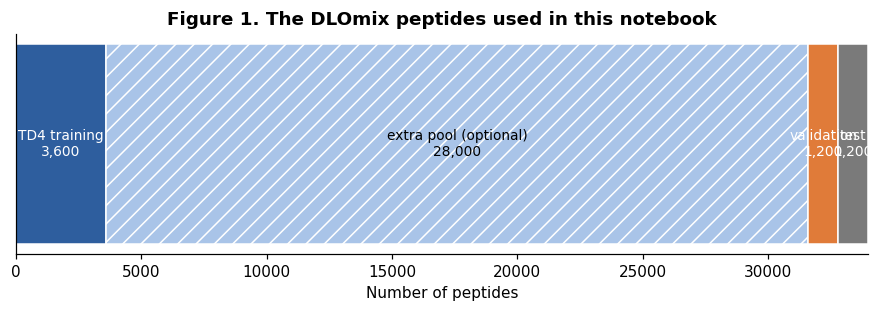

In [3]:
# --- Figure 1: one horizontal bar divided into the parts of the data --------------------
fig, ax = plt.subplots(figsize=(10, 2.6))   # create an empty figure with one plot area (ax)

# A list of (label, number of peptides, colour) for each part of the bar
parts = [("TD4 training", len(train), "#2E5E9E"), ("extra pool (optional)", len(extra_pool), "#A9C4E8"),
         ("validation", len(validation), "#E07B39"), ("test", len(test), "#7A7A7A")]
left = 0                                    # where the next part of the bar starts
for label, n, color in parts:               # draw the parts one after the other
    ax.barh(0, n, left=left, color=color, edgecolor="white", hatch="//" if "extra" in label else None)
    ax.text(left + n / 2, 0, f"{label}\n{n:,}", ha="center", va="center", fontsize=9,
            color="white" if color != "#A9C4E8" else "black")   # label in the middle of the part
    left += n                               # move the start position to the end of this part
ax.set(yticks=[], xlabel="Number of peptides", xlim=(0, left))
ax.grid(False)
ax.set_title("Figure 1. The DLOmix peptides used in this notebook", fontweight="bold")
plt.show()                                  # display the figure

## 3. Settings panel

In Colab, the cell below shows a form with menus and sliders next to the code. Change a value,
then run the cells from here downwards. The table explains each setting.

| Setting | What it does |
|---|---|
| `MODEL_TYPE` | `gru` reads the peptide residue by residue in both directions. `transformer` lets every residue look at every other residue (self-attention). `cnn` slides small filters along the sequence. |
| `EXTRA_TRAINING_PEPTIDES` | How many peptides from the extra pool to add to the 3,600 TD4 training peptides. |
| `EMBEDDING_SIZE` | How many numbers describe each residue inside the model. Larger means more capacity. |
| `NUM_LAYERS` | How many processing layers are stacked. More layers can learn more complex patterns. |
| `NUM_HEADS` | Transformer only: how many attention patterns are learned in parallel. `EMBEDDING_SIZE` must be divisible by it. |
| `DROPOUT` | Fraction of internal values randomly set to zero during training. It discourages memorisation. |
| `COUNT_POSITIONS_FROM_BOTH_ENDS` | If on, each residue also knows its distance from the C-terminus, not only from the N-terminus. |
| `EPOCHS` | How many passes over the training peptides. |
| `LEARNING_RATE` | Size of the learning steps. Too large is unstable; too small learns slowly. |
| `BATCH_SIZE` | How many peptides are used for each learning step. |

In [4]:
# @title Settings (change these, then run the cells below) { display-mode: "both" }
# In Colab, each "# @param" comment turns the line into a menu, slider or check box.
# Outside Colab, simply edit the values after the = signs.
MODEL_TYPE = "gru"  # @param ["gru", "transformer", "cnn"]
EXTRA_TRAINING_PEPTIDES = 28000  # @param {type:"slider", min:0, max:28000, step:1000}
EMBEDDING_SIZE = 64  # @param [32, 64, 128] {type:"raw"}
NUM_LAYERS = 1  # @param {type:"slider", min:1, max:6, step:1}
NUM_HEADS = 4  # @param [1, 2, 4, 8] {type:"raw"}
DROPOUT = 0.1  # @param {type:"slider", min:0, max:0.5, step:0.05}
COUNT_POSITIONS_FROM_BOTH_ENDS = True  # @param {type:"boolean"}
EPOCHS = 30  # @param {type:"slider", min:5, max:300, step:5}
LEARNING_RATE = 0.003  # @param [0.0003, 0.001, 0.003, 0.01] {type:"raw"}
BATCH_SIZE = 64  # @param [32, 64, 128, 256] {type:"raw"}
SEED = 42  # @param {type:"integer"}

# Collect all settings in one dictionary, so that we can pass them to functions in one go
settings = dict(model_type=MODEL_TYPE, extra=EXTRA_TRAINING_PEPTIDES, size=EMBEDDING_SIZE,
                layers=NUM_LAYERS, heads=NUM_HEADS, dropout=DROPOUT,
                both_ends=COUNT_POSITIONS_FROM_BOTH_ENDS, epochs=EPOCHS, lr=LEARNING_RATE,
                batch=BATCH_SIZE, seed=SEED)

# A Transformer splits each embedding into NUM_HEADS equal parts, so the division must be exact.
# % gives the remainder of a division; 0 means "divides exactly".
if MODEL_TYPE == "transformer":
    assert EMBEDDING_SIZE % NUM_HEADS == 0, "EMBEDDING_SIZE must be divisible by NUM_HEADS"

# The training set = the 3,600 TD4 training peptides + the first N peptides of the extra pool.
# pd.concat glues tables together, one below the other; .head(N) takes the first N rows.
training_set = pd.concat([train, extra_pool.head(EXTRA_TRAINING_PEPTIDES)], ignore_index=True)
print(f"Model: {MODEL_TYPE} | training peptides: {len(training_set):,} "
      f"(3,600 TD4 + {EXTRA_TRAINING_PEPTIDES:,} extra) | device: {DEVICE.type}")

Model: gru | training peptides: 31,600 (3,600 TD4 + 28,000 extra) | device: cpu


## 4. From letters to numbers

A neural network only works with numbers. Each residue gets three numbers:

- a **token**: the amino acid as an integer from 1 to 20 (0 is used to fill up short peptides);
- its **position from the N-terminus** (0, 1, 2, ...);
- its **position from the C-terminus** (optional, see the settings).

Inside the model, each of these integers is replaced by a vector of `EMBEDDING_SIZE` numbers
(an **embedding**). The values of the embeddings are not chosen by us: the model learns them
during training. Section 7 shows what the model learned.

All peptides are padded with zeros to the same length (50), because the GPU processes many
peptides at once as one rectangular table of numbers.

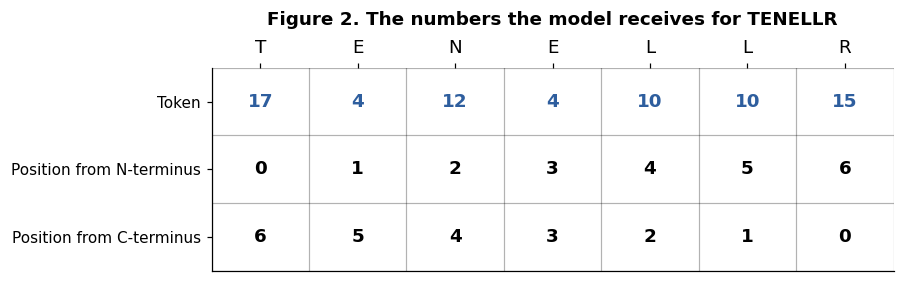

In [5]:
# A dictionary that gives each amino acid an integer: A -> 1, C -> 2, ..., Y -> 20.
# enumerate() numbers the letters 0, 1, 2, ...; we add 1 because 0 is reserved for padding.
TOKEN = {aa: i + 1 for i, aa in enumerate(AMINO_ACIDS)}
MAX_LENGTH = 50     # every peptide is stored as 50 positions; the longest DLOmix peptide has 40


def encode(sequences):
    """Turn peptides into a (number of peptides, MAX_LENGTH) table of tokens, padded with 0."""
    sequences = list(sequences)
    tokens = np.zeros((len(sequences), MAX_LENGTH), dtype=np.int64)   # a table full of zeros
    for n, sequence in enumerate(sequences):          # n = row number, sequence = the peptide
        # Write the tokens of this peptide at the start of row n; the rest of the row stays 0
        tokens[n, :len(sequence)] = [TOKEN[aa] for aa in sequence[:MAX_LENGTH]]
    return torch.tensor(tokens)                       # convert to a PyTorch tensor (GPU-ready array)


# --- Figure 2: show the three numbers of each residue for one example peptide ----------
example = "TENELLR"
rows = {"Token": encode([example])[0, :len(example)].numpy(),   # row 0 of the table, real residues only
        "Position from N-terminus": np.arange(len(example)),    # 0, 1, 2, ..., 6
        "Position from C-terminus": np.arange(len(example))[::-1]}   # [::-1] reverses: 6, 5, ..., 0
fig, ax = plt.subplots(figsize=(8, 2.4))
ax.imshow(np.zeros((3, len(example))), cmap="Greys", vmin=0, vmax=1, aspect="auto")   # white grid
for r, (label, values) in enumerate(rows.items()):    # r = row number in the figure
    for c, value in enumerate(values):                # c = column (position in the peptide)
        ax.text(c, r, int(value), ha="center", va="center", fontsize=12, fontweight="bold",
                color="#2E5E9E" if r == 0 else "black")
ax.set_xticks(range(len(example)), list(example), fontsize=12)
ax.set_yticks(range(3), list(rows))
ax.xaxis.tick_top()                                   # show the residues above the table
ax.set_xticks(np.arange(-0.5, len(example)), minor=True)   # lines between the cells
ax.set_yticks(np.arange(-0.5, 3), minor=True)
ax.grid(which="minor", color="black", lw=0.8)
ax.grid(which="major", visible=False)
ax.tick_params(which="minor", length=0)
ax.set_title(f"Figure 2. The numbers the model receives for {example}", fontweight="bold", pad=28)
plt.show()

## 5. The model

The cell below contains the model code. You do not need to change it to do the experiments.
The figure after it draws the model that your settings describe.

All three models end in the same way: one predicted iRT value per peptide. The GRU summarises the
peptide in its final memory. The Transformer and the CNN compute one **contribution per residue**
and add them up, like the linear model of TD4, except that each contribution now depends on the
neighbouring residues.

**How PyTorch models are written.** A model is a `class` that inherits from `nn.Module`. Its
`__init__` method creates the parts (layers) and their learnable numbers. Its `forward` method
describes how the input flows through these parts to give the output. PyTorch then works out
automatically how to adjust the learnable numbers during training.

**What the tensor shapes mean.** In the comments, `[peptides, positions, size]` means a block of
numbers with one entry per peptide in the batch, per position (50) and per embedding value.

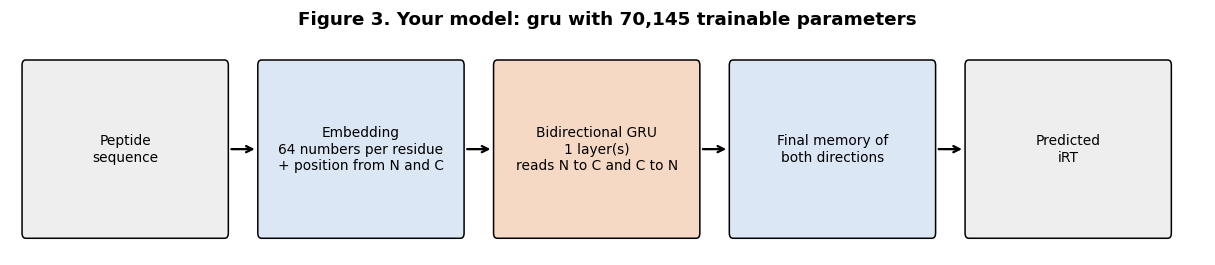

In [6]:
# @title Model code { display-mode: "both" }

class PeptideEmbedding(nn.Module):
    """Residue embedding + position from the N-terminus (+ optionally from the C-terminus)."""

    def __init__(self, size, both_ends, dropout):
        super().__init__()                               # standard first line of every nn.Module
        # nn.Embedding is a learnable lookup table: integer -> vector of `size` numbers.
        # 21 rows: 20 amino acids + the padding token 0 (padding_idx=0 keeps its vector at zero).
        self.residue = nn.Embedding(len(AMINO_ACIDS) + 1, size, padding_idx=0)
        self.from_n = nn.Embedding(MAX_LENGTH, size)     # one learnable vector per position from N
        self.from_c = nn.Embedding(MAX_LENGTH, size) if both_ends else None   # optional: from C
        # Start the position vectors with small random values, so that at the beginning of
        # training they do not drown the information about the amino acids.
        nn.init.normal_(self.from_n.weight, std=0.02)
        if self.from_c is not None:
            nn.init.normal_(self.from_c.weight, std=0.02)
        self.dropout = nn.Dropout(dropout)               # randomly zeroes values during training

    def forward(self, tokens):                           # tokens: [peptides, positions] integers
        mask = tokens != 0                               # True for real residues, False for padding
        # position: 0, 1, 2, ... for every peptide in the batch
        position = torch.arange(tokens.shape[1], device=tokens.device).expand_as(tokens)
        x = self.residue(tokens) + self.from_n(position) # add residue and position vectors
        if self.from_c is not None:
            # distance from the C-terminus = length - 1 - position (clamped to 0 for padding)
            from_c = (mask.sum(1, keepdim=True) - 1 - position).clamp(min=0)
            x = x + self.from_c(from_c)
        # Multiply by the mask so that padding positions stay exactly zero
        return self.dropout(x * mask.unsqueeze(-1)), mask    # x: [peptides, positions, size]


class TransformerBlock(nn.Module):
    """Self-attention (every residue looks at all others), then a small feed-forward network."""

    def __init__(self, size, heads, dropout):
        super().__init__()
        self.norm1 = nn.LayerNorm(size)                  # rescales the values of each residue
        # Multi-head self-attention: each residue builds a weighted mix of all residues
        self.attention = nn.MultiheadAttention(size, heads, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(size)
        # Feed-forward network applied to each residue separately: widen, non-linearity, narrow
        self.feed_forward = nn.Sequential(nn.Linear(size, 4 * size), nn.GELU(), nn.Dropout(dropout),
                                          nn.Linear(4 * size, size))
        self.dropout = nn.Dropout(dropout)
        self.last_attention = None                       # filled in when we want to plot attention

    def forward(self, x, mask, store_attention=False):
        h = self.norm1(x)
        # key_padding_mask=~mask tells the attention to ignore the padding positions
        attended, weights = self.attention(h, h, h, key_padding_mask=~mask, need_weights=store_attention,
                                           average_attn_weights=False)
        self.last_attention = weights.detach() if store_attention else None
        x = x + self.dropout(attended)                   # "residual connection": add, do not replace
        return x + self.dropout(self.feed_forward(self.norm2(x)))


class RetentionModel(nn.Module):
    """The full model: embedding -> GRU, Transformer or CNN -> one predicted value per peptide."""

    def __init__(self, model_type, size, layers, heads, dropout, both_ends):
        super().__init__()
        self.model_type = model_type
        self.embedding = PeptideEmbedding(size, both_ends, dropout)
        if model_type == "gru":
            # Bidirectional GRU: one GRU reads N -> C, a second one reads C -> N
            self.gru = nn.GRU(size, size, num_layers=layers, batch_first=True, bidirectional=True,
                              dropout=dropout if layers > 1 else 0)
            self.summary = nn.Linear(2 * size, size)     # combine the memories of both directions
            # Small network that turns the summary into one number
            self.head = nn.Sequential(nn.Linear(size, size), nn.GELU(), nn.Dropout(dropout), nn.Linear(size, 1))
        else:
            if model_type == "transformer":
                # nn.ModuleList holds several blocks; the list comprehension builds `layers` of them
                self.blocks = nn.ModuleList([TransformerBlock(size, heads, dropout) for _ in range(layers)])
            elif model_type == "cnn":
                # Each convolution looks at 3 positions; the dilation (1, 2, 4, ...) spreads them
                # further apart in each layer, so deeper layers see wider windows of the peptide
                self.convs = nn.ModuleList([nn.Conv1d(size, size, 3, padding=2 ** i, dilation=2 ** i)
                                            for i in range(layers)])
            else:
                raise ValueError(f"Unknown MODEL_TYPE: {model_type}")   # stop with a clear message
            self.final_norm = nn.LayerNorm(size)
            # Small network applied to each residue: its vector -> one contribution (a number)
            self.contribution = nn.Sequential(nn.Linear(size, size), nn.GELU(), nn.Linear(size, 1))

    def forward(self, tokens, store_attention=False):
        x, mask = self.embedding(tokens)                 # [peptides, positions, size]
        if self.model_type == "gru":
            # "Packing" tells the GRU the real length of each peptide, so it skips the padding
            packed = nn.utils.rnn.pack_padded_sequence(x, mask.sum(1).cpu(), batch_first=True,
                                                       enforce_sorted=False)
            _, memory = self.gru(packed)                 # final memory of both reading directions
            both = torch.cat([memory[-2], memory[-1]], dim=1)   # put the two memories side by side
            return self.head(self.summary(both)).squeeze(-1)    # one number per peptide
        if self.model_type == "transformer":
            for block in self.blocks:                    # pass through the blocks one after the other
                x = block(x, mask, store_attention)
        else:
            h = x.transpose(1, 2)                        # Conv1d expects [peptides, size, positions]
            for conv in self.convs:
                h = h + nn.functional.gelu(conv(h)) * mask.unsqueeze(1)   # residual + keep padding at 0
            x = h.transpose(1, 2)                        # back to [peptides, positions, size]
        per_residue = self.contribution(self.final_norm(x)).squeeze(-1) * mask   # [peptides, positions]
        return per_residue.sum(dim=1)                    # add up the contributions of each peptide


def build_model(s):
    """Create a new, untrained model from a settings dictionary."""
    return RetentionModel(s["model_type"], s["size"], s["layers"], s["heads"], s["dropout"], s["both_ends"])


def draw_architecture(s):
    """Draw the model described by the settings as a row of boxes (Figure 3)."""
    # The text of the middle box depends on the model type: look it up in a dictionary
    middle = {
        "gru": f"Bidirectional GRU\n{s['layers']} layer(s)\nreads N to C and C to N",
        "transformer": f"Transformer\n{s['layers']} block(s), {s['heads']} heads\nself-attention\n+ feed-forward",
        "cnn": f"Dilated CNN\n{s['layers']} layer(s)\nwindows of 3, 5, 9,\n... residues",
    }[s["model_type"]]
    combine = ("Final memory of\nboth directions" if s["model_type"] == "gru"
               else "One contribution\nper residue,\nadded up")
    boxes = [("Peptide\nsequence", "#EEEEEE"),
             (f"Embedding\n{s['size']} numbers per residue\n+ position from N"
              + (" and C" if s["both_ends"] else ""), "#DCE7F5"),
             (middle, "#F6D9C4"), (combine, "#DCE7F5"), ("Predicted\niRT", "#EEEEEE")]
    fig, ax = plt.subplots(figsize=(14, 2.6))
    width, gap = 2.7, 0.5                                # box width and space between boxes
    for i, (text, color) in enumerate(boxes):
        x0 = i * (width + gap)                           # left edge of box number i
        ax.add_patch(FancyBboxPatch((x0, 0), width, 1.6, boxstyle="round,pad=0.05", fc=color, ec="black"))
        ax.text(x0 + width / 2, 0.8, text, ha="center", va="center", fontsize=9)
        if i < len(boxes) - 1:                           # an arrow to the next box (not after the last)
            ax.annotate("", xy=(x0 + width + gap - 0.05, 0.8), xytext=(x0 + width + 0.05, 0.8),
                        arrowprops={"arrowstyle": "->", "lw": 1.5})
    ax.set(xlim=(-0.2, len(boxes) * (width + gap)), ylim=(-0.2, 1.9))
    ax.axis("off")
    # Count the learnable numbers (parameters) of a fresh model with these settings
    n_parameters = sum(p.numel() for p in build_model(s).parameters())
    ax.set_title(f"Figure 3. Your model: {s['model_type']} with {n_parameters:,} trainable parameters",
                 fontweight="bold")
    plt.show()


draw_architecture(settings)

### Optional: how much faster is the GPU?

This cell times 30 learning steps of your model on the CPU and on the GPU. It only runs when a GPU
is available. A GPU is fast because it performs thousands of simple calculations in parallel,
which is exactly what neural networks need.

In [7]:
def time_steps(device, n_steps=30):
    """Return the average time (in seconds) of one learning step on the given device."""
    torch.manual_seed(0)
    model = build_model(settings).to(device)             # .to(device) moves the model to CPU or GPU
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    tokens = encode(training_set["sequence"].iloc[:BATCH_SIZE * n_steps]).to(device)
    target = torch.zeros(len(tokens), device=device)     # dummy targets: we only measure speed
    for step in range(n_steps + 3):                      # 3 warm-up steps are not timed
        if step == 3:
            if device.type == "cuda":
                torch.cuda.synchronize()                 # wait until the GPU has finished its work
            start = time.time()
        batch = slice((step % n_steps) * BATCH_SIZE, (step % n_steps + 1) * BATCH_SIZE)
        optimizer.zero_grad()
        nn.functional.smooth_l1_loss(model(tokens[batch]), target[batch]).backward()
        optimizer.step()
    if device.type == "cuda":
        torch.cuda.synchronize()
    return (time.time() - start) / n_steps


if DEVICE.type == "cuda":
    timings = {"CPU": time_steps(torch.device("cpu")), "GPU": time_steps(DEVICE)}
    fig, ax = plt.subplots(figsize=(6, 3))
    bars = ax.bar(timings.keys(), [1000 * t for t in timings.values()], color=["#9E9E9E", "#76B900"])
    ax.bar_label(bars, fmt="%.1f ms")                    # write the value on top of each bar
    ax.set(ylabel="Time per learning step (ms)",
           title=f"Figure 4. GPU is {timings['CPU'] / timings['GPU']:.0f}x faster for this model")
    plt.show()
else:
    print("No GPU available: speed comparison skipped.")

No GPU available: speed comparison skipped.


## 6. Train the model

Run the cell below to train with the current settings. The plot updates during training:

- **left**: the error (MAE) on training and validation peptides after each epoch, with the TD4
  references as dashed lines;
- **right**: the learning rate. It rises during the first epochs (warm-up) and then decreases
  smoothly, so the model can settle at the end.

The model from the epoch with the lowest validation error is kept. Training on a GPU is not exactly
reproducible, so repeated runs can differ slightly.

**What one learning step does** (the inner loop of `train_run`):

1. take a **batch** of training peptides;
2. **predict** their iRT with the current model (`model(...)`);
3. compute the **loss**: how far the predictions are from the recorded values;
4. **backpropagation** (`loss.backward()`): PyTorch computes, for every learnable number, in which
   direction it should change to reduce the loss;
5. the **optimizer** (`optimizer.step()`) changes all learnable numbers a little in that direction.

One **epoch** repeats this until every training peptide has been used once.

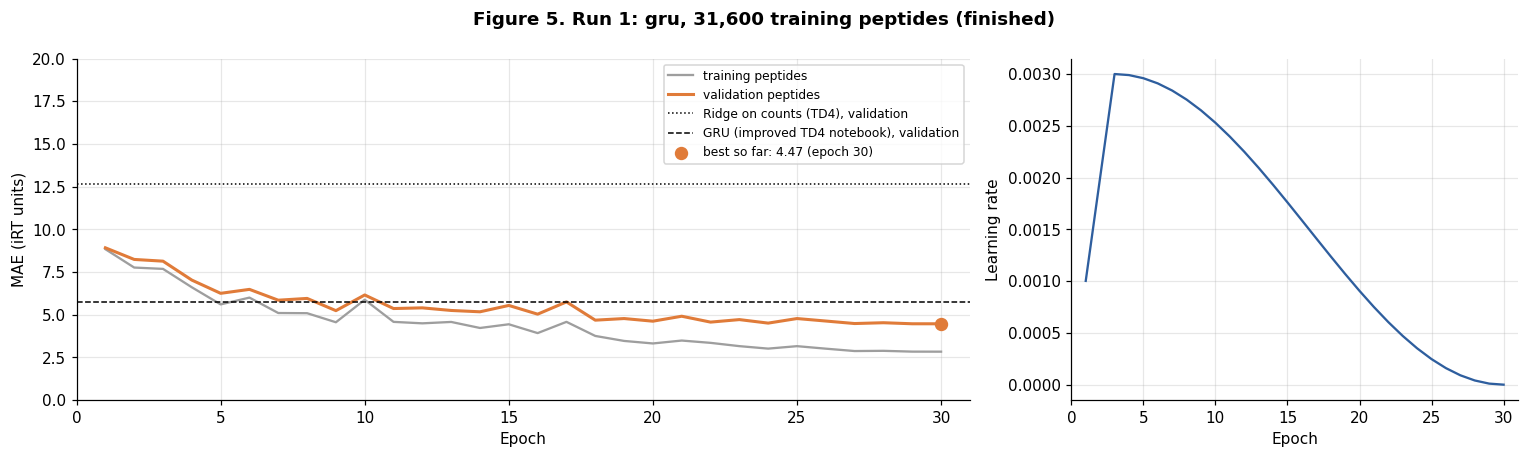

Run 1 finished in 8.1 min. Best validation MAE 4.47 iRT units at epoch 30 (training MAE 2.84).


In [8]:
def plot_training(history, settings, run, finished, eta=None):
    """Draw Figure 5 from the list of per-epoch results collected so far."""
    h = pd.DataFrame(history)                            # list of dictionaries -> table
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [2, 1]})
    axes[0].plot(h["epoch"], h["train_mae"], color="#9E9E9E", label="training peptides")
    axes[0].plot(h["epoch"], h["val_mae"], color="#E07B39", lw=2, label="validation peptides")
    # zip pairs each reference with a line style (dotted, dashed)
    for (name, ref), style in zip(REFERENCES.items(), [":", "--"]):
        axes[0].axhline(ref["validation"], color="black", ls=style, lw=1, label=f"{name}, validation")
    best = h.loc[h["val_mae"].idxmin()]                  # the row (epoch) with the lowest validation error
    axes[0].scatter(best["epoch"], best["val_mae"], color="#E07B39", s=60, zorder=3,
                    label=f"best so far: {best['val_mae']:.2f} (epoch {int(best['epoch'])})")
    axes[0].set(xlim=(0, settings["epochs"] + 1), ylim=(0, 20), xlabel="Epoch",
                ylabel="MAE (iRT units)")
    axes[0].legend(fontsize=8, loc="upper right")
    axes[1].plot(h["epoch"], h["lr"], color="#2E5E9E")
    axes[1].set(xlim=(0, settings["epochs"] + 1), xlabel="Epoch", ylabel="Learning rate")
    status = "finished" if finished else f"training, about {eta:.0f} s left"
    fig.suptitle(f"Figure 5. Run {run}: {settings['model_type']}, {len(training_set):,} training peptides "
                 f"({status})", fontweight="bold")
    fig.tight_layout()
    plt.show()


def train_run(settings, live_plot=True):
    """Train one model with the given settings, store it in the experiment log, return its run number."""
    # Fix the random number generators so that a run can be repeated (exactly on CPU)
    torch.manual_seed(settings["seed"])
    generator = torch.Generator().manual_seed(settings["seed"])
    run = len(experiment_log) + 1                        # run number: 1, 2, 3, ...
    model = build_model(settings).to(DEVICE)             # a new, untrained model on the CPU or GPU

    # --- Prepare the data as tensors on the device ---
    x_train = encode(training_set["sequence"]).to(DEVICE)
    x_val = encode(validation["sequence"]).to(DEVICE)
    y_train, y_val = training_set["irt"].to_numpy(), validation["irt"].to_numpy()
    # Neural networks learn better when the target is around 0 with a spread of about 1.
    # We rescale iRT with the mean and standard deviation of the TRAINING peptides only.
    mean, std = float(y_train.mean()), float(y_train.std())
    target = torch.tensor((y_train - mean) / std, dtype=torch.float32, device=DEVICE)
    monitor = slice(0, 2000)                             # 2,000 training peptides used to plot the training error

    # --- The optimizer changes the learnable numbers; the scheduler changes the learning rate ---
    optimizer = torch.optim.AdamW(model.parameters(), lr=settings["lr"], weight_decay=0.01)
    steps_per_epoch = math.ceil(len(target) / settings["batch"])   # math.ceil rounds up
    warmup = max(1, min(5, settings["epochs"] // 10)) * steps_per_epoch   # warm-up: up to 5 epochs
    total = settings["epochs"] * steps_per_epoch

    def lr_factor(step):
        """Multiplier of the learning rate at a given step: linear warm-up, then cosine decay to 0."""
        if step < warmup:
            return (step + 1) / warmup
        return 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total - warmup)))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)

    def predict_tokens(tokens):
        """Predict iRT (in iRT units) for encoded peptides, 2,048 at a time."""
        model.eval()                                     # evaluation mode: dropout switched off
        with torch.no_grad():                            # no learning here, so no gradients needed
            out = torch.cat([model(tokens[i:i + 2048]).float().cpu() for i in range(0, len(tokens), 2048)])
        return out.numpy() * std + mean                  # undo the rescaling of the target

    history, best = [], {"mae": np.inf}                  # np.inf = infinity: any error is better
    plot_every = max(1, settings["epochs"] // 15)        # refresh the plot about 15 times per run
    start = time.time()
    for epoch in range(1, settings["epochs"] + 1):       # one epoch = one pass over all training peptides
        model.train()                                    # training mode: dropout switched on
        order = torch.randperm(len(target), generator=generator).to(DEVICE)   # shuffle the peptides
        for i in range(0, len(order), settings["batch"]):
            batch = order[i:i + settings["batch"]]       # the indices of the peptides in this batch
            optimizer.zero_grad(set_to_none=True)        # forget the gradients of the previous step
            # Loss: smooth L1 behaves like the absolute error, but is gentler near zero
            loss = nn.functional.smooth_l1_loss(model(x_train[batch]), target[batch])
            loss.backward()                              # backpropagation: compute the gradients
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # limit very large steps
            optimizer.step()                             # update the learnable numbers
            scheduler.step()                             # update the learning rate
        # After each epoch: measure the errors and remember the results
        val_mae = mean_absolute_error(y_val, predict_tokens(x_val))
        train_mae = mean_absolute_error(y_train[monitor], predict_tokens(x_train[monitor]))
        history.append({"epoch": epoch, "train_mae": train_mae, "val_mae": val_mae,
                        "lr": optimizer.param_groups[0]["lr"]})
        if val_mae < best["mae"]:                        # new best validation error: save a copy of the model
            best = {"mae": val_mae, "epoch": epoch, "train_mae": train_mae,
                    "state": copy.deepcopy(model.state_dict())}
        finished = epoch == settings["epochs"]
        if live_plot and (epoch % plot_every == 0 or finished):
            clear_output(wait=True)                      # remove the previous plot
            eta = (time.time() - start) / epoch * (settings["epochs"] - epoch)   # estimated time left
            plot_training(history, settings, run, finished, eta)

    model.load_state_dict(best["state"])                 # go back to the best epoch
    model.eval()
    minutes = (time.time() - start) / 60

    def predict(sequences):
        """Predict iRT for a list of peptide sequences (letters)."""
        return predict_tokens(encode(sequences).to(DEVICE))

    # Add one row to the experiment log (a dictionary: column name -> value)
    experiment_log.append({
        "run": run, "model": settings["model_type"], "training peptides": len(training_set),
        "embedding size": settings["size"], "layers": settings["layers"],
        "heads": settings["heads"] if settings["model_type"] == "transformer" else "",
        "dropout": settings["dropout"], "both ends": settings["both_ends"], "epochs": settings["epochs"],
        "learning rate": settings["lr"], "batch": settings["batch"], "best epoch": best["epoch"],
        "training MAE": round(best["train_mae"], 2), "validation MAE": round(best["mae"], 2),
        "minutes": round(minutes, 1), "device": DEVICE.type,
    })
    trained_models[run] = {"model": model, "predict": predict, "settings": dict(settings),
                           "history": pd.DataFrame(history)}
    print(f"Run {run} finished in {minutes:.1f} min. Best validation MAE {best['mae']:.2f} iRT units "
          f"at epoch {best['epoch']} (training MAE {best['train_mae']:.2f}).")
    return run


# Train with the current settings, then keep shortcuts to the trained model and its predict function
current_run = train_run(settings)
model, predict = trained_models[current_run]["model"], trained_models[current_run]["predict"]

**How to read Figure 5.**

- Both curves going down: the model is still learning. If they are still falling at the last epoch,
  try more epochs.
- Training error much lower than validation error: the model starts to memorise the training
  peptides (overfitting). Try more dropout, a smaller model or more training peptides.
- Curves jumping up and down strongly: the learning rate may be too large.
- The dashed lines show the TD4 references. Your model is useful if its validation error is below them.

## 7. Look inside the trained model

### 7.1 How good are the validation predictions?

The left plot compares predicted and recorded iRT for each validation peptide. The right plot
groups the peptides by length and shows the average error in each group, for this run and for
the TD4 Ridge model.

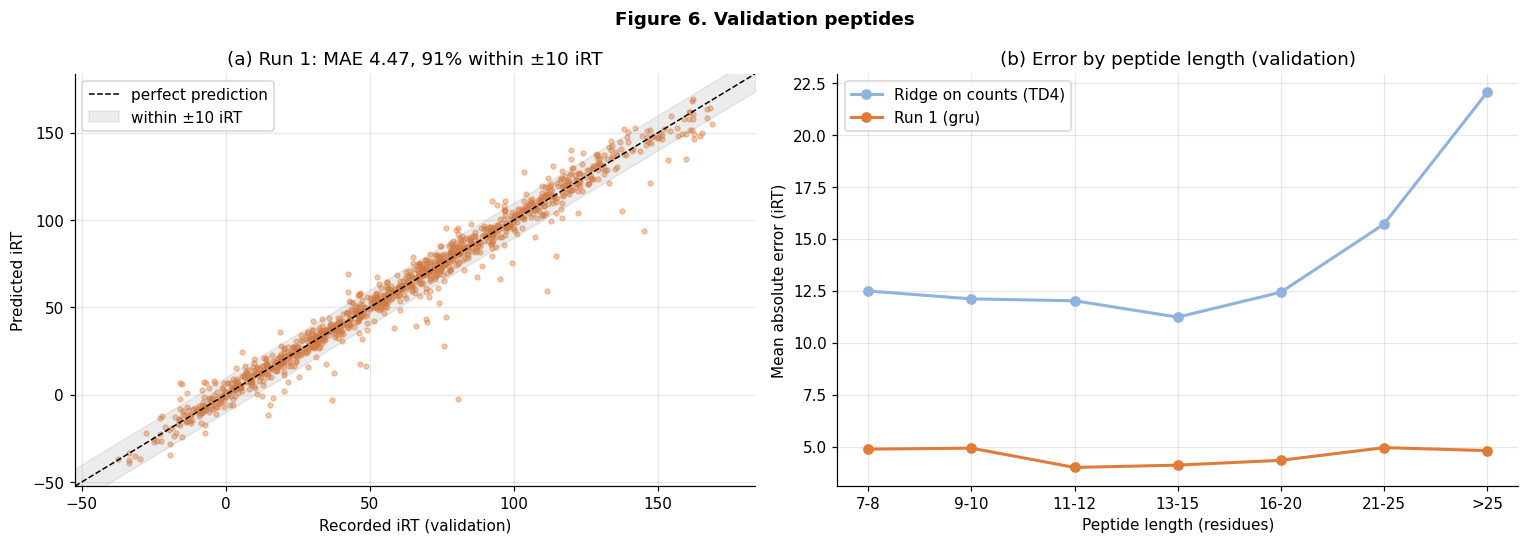

In [9]:
val_pred = predict(validation["sequence"])                              # this run
ridge_val_pred = ridge.predict(count_features(validation["sequence"]))  # TD4 reference
y_val = validation["irt"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))           # two plots side by side: axes[0], axes[1]

# (a) Predicted against recorded iRT; points on the dashed diagonal are perfect predictions
limits = [y_val.min() - 15, y_val.max() + 15]
axes[0].scatter(y_val, val_pred, s=10, alpha=0.4, color="#E07B39")
axes[0].plot(limits, limits, "k--", lw=1, label="perfect prediction")
# Grey band: predictions within ±10 iRT units of the recorded value (a list comprehension builds the edges)
axes[0].fill_between(limits, [l - 10 for l in limits], [l + 10 for l in limits], color="grey",
                     alpha=0.15, label="within ±10 iRT")
axes[0].set(xlim=limits, ylim=limits, xlabel="Recorded iRT (validation)", ylabel="Predicted iRT",
            title=f"(a) Run {current_run}: MAE {mean_absolute_error(y_val, val_pred):.2f}, "
                  f"{np.mean(np.abs(y_val - val_pred) <= 10):.0%} within ±10 iRT")
axes[0].legend(loc="upper left")

# (b) Mean absolute error per length group. pd.cut assigns each peptide to a length group.
labels = ["7-8", "9-10", "11-12", "13-15", "16-20", "21-25", ">25"]
group = pd.cut(validation["sequence"].str.len(), [0, 8, 10, 12, 15, 20, 25, 100], labels=labels)
for name, prediction, color in [("Ridge on counts (TD4)", ridge_val_pred, "#8FB3DE"),
                                (f"Run {current_run} ({MODEL_TYPE})", val_pred, "#E07B39")]:
    error = pd.Series(np.abs(y_val - prediction), index=validation.index)
    # groupby(...).mean() averages the errors within each length group
    axes[1].plot(labels, error.groupby(group, observed=False).mean(), "o-", lw=2, color=color, label=name)
axes[1].set(xlabel="Peptide length (residues)", ylabel="Mean absolute error (iRT)",
            title="(b) Error by peptide length (validation)")
axes[1].legend()
fig.suptitle("Figure 6. Validation peptides", fontweight="bold")
fig.tight_layout()
plt.show()

### 7.2 What did the model learn about amino acids?

Each amino acid is represented inside the model by `EMBEDDING_SIZE` learned numbers. We cannot
plot so many dimensions, so we use a **principal component analysis (PCA)** to project them onto
the two directions that show the largest differences between amino acids. Amino acids that the
model treats similarly end up close together. The model was never told which amino acids are
hydrophobic or charged.

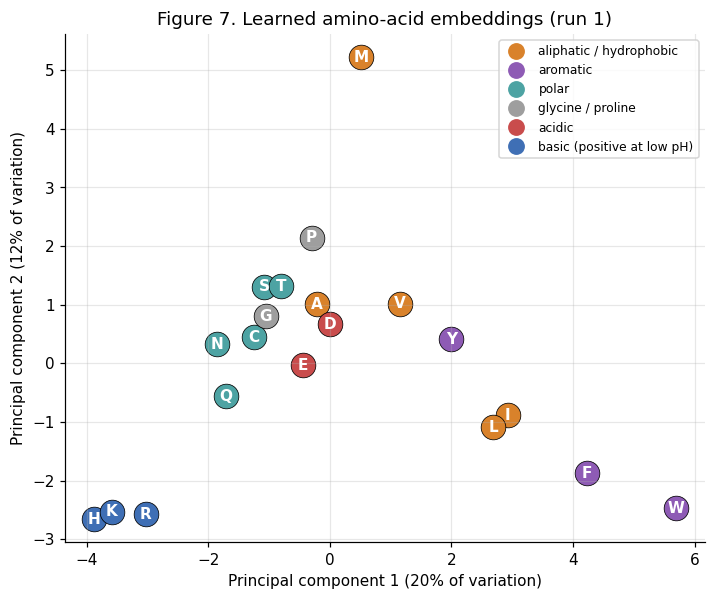

In [10]:
# Take the learned embedding table out of the model: 21 rows (padding + 20 amino acids).
# .detach().cpu().numpy() converts a PyTorch tensor (possibly on the GPU) into a NumPy array.
vectors = model.embedding.residue.weight.detach().cpu().numpy()[1:]   # [1:] skips row 0 (padding)

# PCA with NumPy: centre the data, then a singular value decomposition (SVD) finds the
# directions of largest variation. The first two give the x and y coordinates of the plot.
centred = vectors - vectors.mean(axis=0)
u, s, _ = np.linalg.svd(centred, full_matrices=False)
coordinates = u[:, :2] * s[:2]                    # coordinates of each amino acid on the 2 main axes
explained = s[:2] ** 2 / np.sum(s ** 2)           # fraction of the variation shown by each axis

fig, ax = plt.subplots(figsize=(7.5, 6))
for aa, (x, y) in zip(AMINO_ACIDS, coordinates):  # zip pairs each letter with its coordinates
    ax.scatter(x, y, s=260, color=CLASS_COLORS[AA_CLASS[aa]], edgecolor="black", lw=0.5)
    ax.text(x, y, aa, ha="center", va="center", fontweight="bold", color="white")
# Legend: one coloured dot per chemical class
handles = [plt.Line2D([], [], marker="o", ls="", ms=10, color=c) for c in CLASS_COLORS.values()]
ax.legend(handles, CLASS_COLORS.keys(), fontsize=8, loc="best")
ax.set(xlabel=f"Principal component 1 ({explained[0]:.0%} of variation)",
       ylabel=f"Principal component 2 ({explained[1]:.0%} of variation)",
       title=f"Figure 7. Learned amino-acid embeddings (run {current_run})")
plt.show()

**What to look for in Figure 7.** Are amino acids of the same chemical class (same colour) close
together? Are the basic residues K, R and H separated from the hydrophobic ones? Compare with the
retention contributions of the linear model in the improved TD4 notebook. The map can change
between runs, because the directions of a PCA have no fixed meaning; only the distances matter.

### 7.3 Which residues matter for one peptide? An in-silico mutation scan

We replace each residue of a peptide, one at a time, by each of the 20 amino acids and predict the
iRT of every variant. The heatmap shows the change in predicted iRT. The bar chart above it
summarises, for each position, the average size of the change: positions with tall bars are the
ones the model is most sensitive to.

Type any peptide in the form below (standard amino acids only).

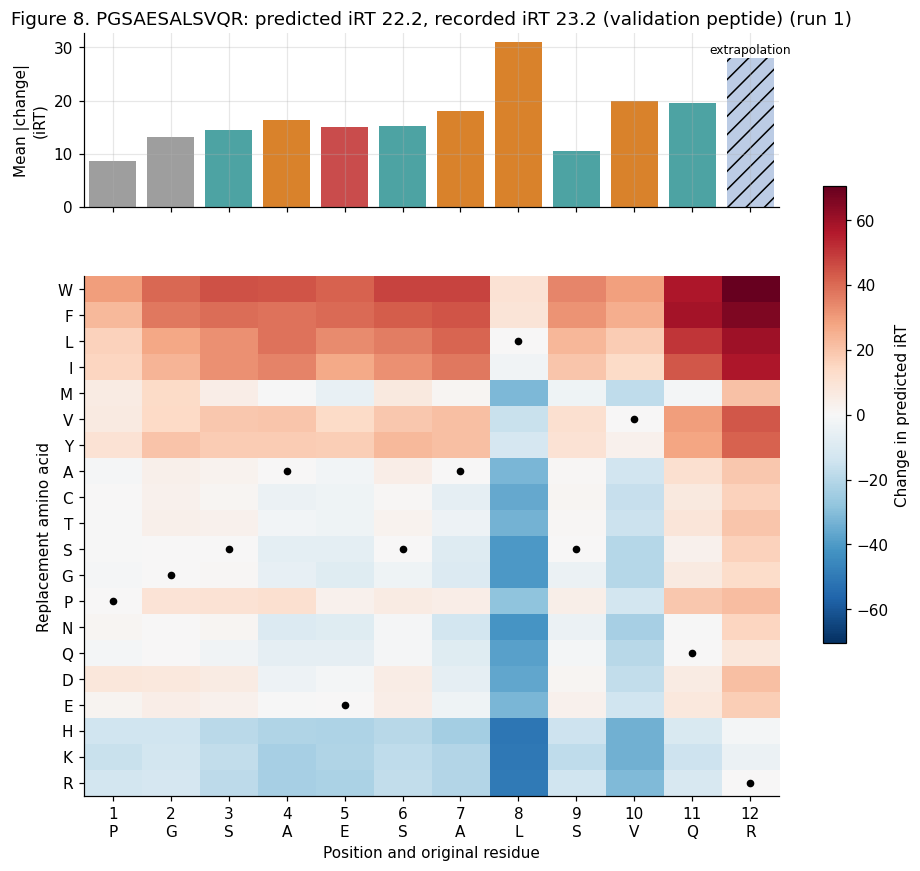

In [11]:
# @title Explain a peptide { display-mode: "both" }
MY_PEPTIDE = "PGSAESALSVQR"  # @param {type:"string"}


def explain_peptide(sequence, run=None):
    """Mutation scan of one peptide with a trained model (the current run by default)."""
    run = run or current_run                             # use the current run if no run is given
    predict_run = trained_models[run]["predict"]
    sequence = sequence.strip().upper()                  # remove spaces, use capital letters
    unknown = set(sequence) - set(AMINO_ACIDS)           # letters that are not standard amino acids
    assert sequence and not unknown, f"Use only the 20 standard amino acids (found: {unknown or 'empty'})"
    assert len(sequence) <= MAX_LENGTH, f"Peptides longer than {MAX_LENGTH} residues are not supported"

    reference = predict_run([sequence])[0]               # prediction for the original peptide
    # Build every single-residue variant: for each position p and each amino acid aa,
    # take the letters before p, put aa at p, and keep the letters after p.
    variants = [sequence[:p] + aa + sequence[p + 1:] for p in range(len(sequence)) for aa in AMINO_ACIDS]
    # Predict all variants at once, subtract the original prediction, and arrange the results
    # as a table with one column per position and one row per amino acid (.T swaps rows and columns)
    change = (predict_run(variants) - reference).reshape(len(sequence), len(AMINO_ACIDS)).T
    row_order = list("WFLIMVYACTSGPNQDEHKR")             # rows roughly from hydrophobic to basic
    change = pd.DataFrame(change, index=list(AMINO_ACIDS)).loc[row_order]
    # Sensitivity of each position: average size of the change over the 19 real substitutions
    sensitivity = change.abs().sum(axis=0) / (len(AMINO_ACIDS) - 1)

    # Is the peptide in the data? Show its recorded value, except for test peptides.
    known = {"training": set(training_set["sequence"]), "validation": set(validation["sequence"]),
             "test": set(test["sequence"])}
    where = next((name for name, seqs in known.items() if sequence in seqs), None)   # first match or None
    if where in ("training", "validation"):
        recorded = full_data.set_index("sequence").loc[sequence, "irt"]
        note = f"recorded iRT {recorded:.1f} ({where} peptide)"
    elif where == "test":
        note = "test peptide: recorded value hidden until the final test"
    else:
        note = "not in the data set: no recorded value"

    # Two plots stacked vertically: sensitivity bars (top) and the heatmap (bottom)
    fig, axes = plt.subplots(2, 1, figsize=(max(7, 0.6 * len(sequence) + 3), 9),
                             gridspec_kw={"height_ratios": [1, 3]}, sharex=True)
    bars = axes[0].bar(range(len(sequence)), sensitivity, color=[CLASS_COLORS[AA_CLASS[aa]] for aa in sequence])
    bars[-1].set(alpha=0.35, hatch="//")                     # C-terminal changes are extrapolations
    axes[0].annotate("extrapolation", (len(sequence) - 1, sensitivity.iloc[-1]), ha="center",
                     xytext=(0, 3), textcoords="offset points", fontsize=8)
    axes[0].set(ylabel="Mean |change|\n(iRT)", title=f"Figure 8. {sequence}: predicted iRT "
                f"{reference:.1f}, {note} (run {run})")
    limit = np.abs(change.to_numpy()).max()              # same colour range for red and blue
    image = axes[1].imshow(change, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
    for p, aa in enumerate(sequence):                    # black dot on the original residue
        axes[1].plot(p, row_order.index(aa), "o", color="black", ms=4)
    axes[1].set_xticks(range(len(sequence)), [f"{p + 1}\n{aa}" for p, aa in enumerate(sequence)])
    axes[1].set_yticks(range(20), row_order)
    axes[1].set(xlabel="Position and original residue", ylabel="Replacement amino acid")
    axes[1].grid(False)
    fig.colorbar(image, ax=axes, label="Change in predicted iRT", shrink=0.6)
    plt.show()
    if sequence[-1] not in "KR":
        print("Note: all training peptides end in K or R. Predictions for other C-terminal residues "
              "are extrapolations and are less reliable.")


explain_peptide(MY_PEPTIDE)

**How to read Figure 8.** Red cells: the variant is predicted to elute later; blue cells: earlier.
Black dots mark the original residues. In the last column, every training peptide had K or R, so
changes there are extrapolations outside the training data and should not be trusted.

### 7.4 Transformer only: which residues look at which?

In a Transformer, each residue gathers information from the other residues through
**self-attention**. The attention weights say how much each residue (row) looks at each other
residue (column); each row adds up to 1. Each **head** learns its own pattern. This cell shows the
last Transformer block for the peptide chosen above.

In [12]:
if trained_models[current_run]["settings"]["model_type"] != "transformer":
    print("This figure is only available for MODEL_TYPE = 'transformer'. "
          "Train a Transformer run (experiment 2) and run this cell again.")
else:
    peptide = MY_PEPTIDE.strip().upper()
    with torch.no_grad():
        # One prediction with store_attention=True: each block keeps its attention weights
        model(encode([peptide]).to(DEVICE), store_attention=True)
    # Attention of the last block for this peptide: [heads, residues, residues], padding removed
    attention = model.blocks[-1].last_attention[0, :, :len(peptide), :len(peptide)].cpu().numpy()
    n_heads = min(4, attention.shape[0])                 # show at most 4 heads
    fig, axes = plt.subplots(1, n_heads, figsize=(4.2 * n_heads, 4.2), squeeze=False)
    for head, ax in enumerate(axes[0]):                  # one heatmap per head
        ax.imshow(attention[head], cmap="Purples", vmin=0)
        ax.set_xticks(range(len(peptide)), list(peptide))
        ax.set_yticks(range(len(peptide)), list(peptide))
        ax.set(xlabel="looks at", ylabel="residue", title=f"head {head + 1}")
        ax.grid(False)
    fig.suptitle(f"Figure 9. Self-attention in the last Transformer block for {peptide}", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()

This figure is only available for MODEL_TYPE = 'transformer'. Train a Transformer run (experiment 2) and run this cell again.


## 8. Compare your runs

Every run of section 6 is added to the experiment log. Use it to answer the questions of the
suggested experiments. Remember: choose between runs with the **validation** error only.

,model,training peptides,embedding size,layers,heads,dropout,both ends,epochs,learning rate,batch,best epoch,training MAE,validation MAE,minutes,device
run,,,,,,,,,,,,,,,
1,gru,31600,64,1,,0.1,True,30,0.003,64,30,2.84,4.47,8.1,cpu


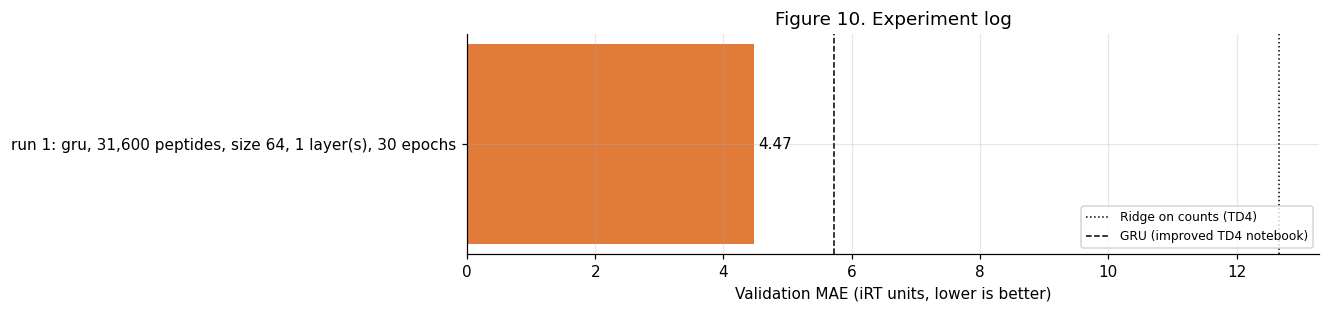

In [13]:
# Turn the list of run dictionaries into a table, with the run number as row label
log = pd.DataFrame(experiment_log).set_index("run")
display(log)

# One horizontal bar per run; the label summarises the main settings of the run
fig, ax = plt.subplots(figsize=(10, 0.6 * len(log) + 2))
labels = [f"run {r}: {row['model']}, {row['training peptides']:,} peptides, size {row['embedding size']}, "
          f"{row['layers']} layer(s), {row['epochs']} epochs" for r, row in log.iterrows()]
bars = ax.barh(labels, log["validation MAE"], color="#E07B39")
ax.bar_label(bars, fmt="%.2f", padding=3)
for (name, ref), style in zip(REFERENCES.items(), [":", "--"]):
    ax.axvline(ref["validation"], color="black", ls=style, lw=1, label=name)
ax.invert_yaxis()                                        # run 1 at the top
ax.set(xlabel="Validation MAE (iRT units, lower is better)", title="Figure 10. Experiment log")
ax.legend(loc="lower right", fontsize=8)
plt.show()

### Optional: how does the amount of training data change the result?

This cell retrains the current model with 0, 4,000, 12,000 and 28,000 extra peptides and plots the
validation error. It takes about four times as long as one training run, so use a GPU. Tick the box
to run it.

In [14]:
# @title Data-size experiment { display-mode: "both" }
RUN_DATA_SIZE_EXPERIMENT = False  # @param {type:"boolean"}

if RUN_DATA_SIZE_EXPERIMENT:
    selected_training_set = training_set                 # remember the training set of the settings
    sizes, errors = [0, 4000, 12000, 28000], []
    for extra in sizes:                                  # one training run per number of extra peptides
        training_set = pd.concat([train, extra_pool.head(extra)], ignore_index=True)
        run = train_run({**settings, "extra": extra}, live_plot=False)   # {**settings, ...}: copy with one change
        errors.append(trained_models[run]["history"]["val_mae"].min())
    training_set = selected_training_set                 # restore the training set of the settings
    n_peptides = [len(train) + extra for extra in sizes]
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.plot(n_peptides, errors, "o-", lw=2, color="#E07B39", label=f"{MODEL_TYPE}")
    for (name, ref), style in zip(REFERENCES.items(), [":", "--"]):
        ax.axhline(ref["validation"], color="black", ls=style, lw=1, label=name)
    ax.set_xscale("log")                                 # logarithmic axis: each doubling has the same width
    ax.set_xticks(n_peptides, [f"{n:,}" for n in n_peptides])
    ax.set(xlabel="Training peptides (log scale)", ylabel="Validation MAE (iRT units)",
           title="Figure 11. Validation error as a function of training-set size")
    ax.legend()
    plt.show()
else:
    print("Skipped. Tick RUN_DATA_SIZE_EXPERIMENT in the form to run it (GPU recommended).")

Skipped. Tick RUN_DATA_SIZE_EXPERIMENT in the form to run it (GPU recommended).


## 9. Final test (run once, at the end)

Choose the run you want to report, based on the validation error only. `"best"` selects the run
with the lowest validation MAE in the log. Then run this cell once. Do not go back and tune the
settings using the test result: the test error would no longer be an independent estimate.

Run 1: test MAE 4.39 iRT units, median error 3.15, 95% of peptides within 12.4

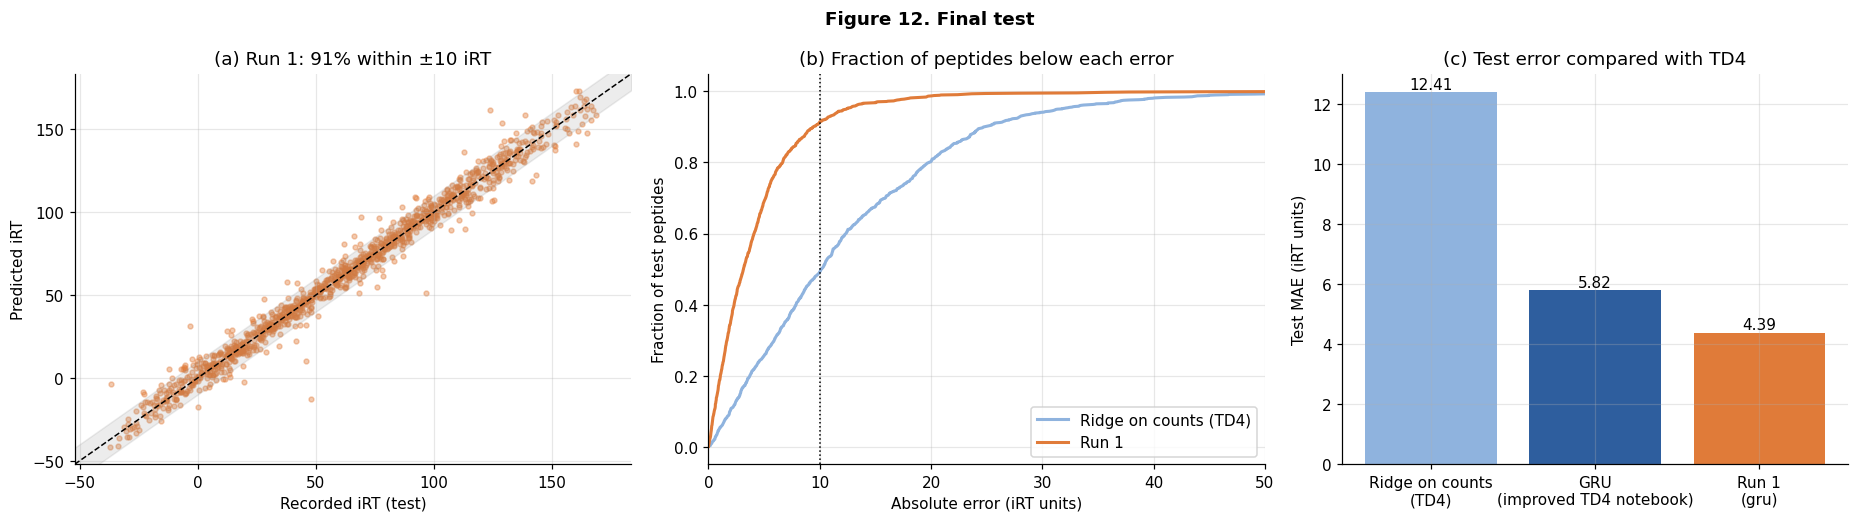

In [15]:
# @title Final test { display-mode: "both" }
TEST_RUN = "best"  # @param {type:"string"}

# Find the run to test: the one with the lowest validation MAE, or the run number typed in the form
chosen = (int(pd.DataFrame(experiment_log).set_index("run")["validation MAE"].idxmin())
          if TEST_RUN == "best" else int(TEST_RUN))
test_pred = trained_models[chosen]["predict"](test["sequence"])
y_test = test["irt"].to_numpy()
test_mae = mean_absolute_error(y_test, test_pred)
ridge_test_pred = ridge.predict(count_features(test["sequence"]))
# np.percentile(..., 95): 95% of the peptides have an error below this value
print(f"Run {chosen}: test MAE {test_mae:.2f} iRT units, median error {np.median(np.abs(y_test - test_pred)):.2f}, "
      f"95% of peptides within {np.percentile(np.abs(y_test - test_pred), 95):.1f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.1, 1.1, 1]})

# (a) Predicted against recorded iRT for the test peptides
limits = [y_test.min() - 15, y_test.max() + 15]
axes[0].scatter(y_test, test_pred, s=10, alpha=0.4, color="#E07B39")
axes[0].plot(limits, limits, "k--", lw=1)
axes[0].fill_between(limits, [l - 10 for l in limits], [l + 10 for l in limits], color="grey", alpha=0.15)
axes[0].set(xlim=limits, ylim=limits, xlabel="Recorded iRT (test)", ylabel="Predicted iRT",
            title=f"(a) Run {chosen}: {np.mean(np.abs(y_test - test_pred) <= 10):.0%} within ±10 iRT")

# (b) Cumulative distribution: sort the errors and plot the fraction of peptides below each value
for name, prediction, color in [("Ridge on counts (TD4)", ridge_test_pred, "#8FB3DE"),
                                (f"Run {chosen}", test_pred, "#E07B39")]:
    error = np.sort(np.abs(y_test - prediction))
    axes[1].plot(error, np.arange(1, len(error) + 1) / len(error), lw=2, color=color, label=name)
axes[1].axvline(10, color="black", ls=":", lw=1)
axes[1].set(xlim=(0, 50), xlabel="Absolute error (iRT units)", ylabel="Fraction of test peptides",
            title="(b) Fraction of peptides below each error")
axes[1].legend(loc="lower right")

# (c) Test MAE of the TD4 references and of the chosen run
names = list(REFERENCES) + [f"Run {chosen}\n({trained_models[chosen]['settings']['model_type']})"]
values = [ref["test"] for ref in REFERENCES.values()] + [test_mae]
bars = axes[2].bar([n.replace(" (", "\n(") for n in names], values, color=["#8FB3DE", "#2E5E9E", "#E07B39"])
axes[2].bar_label(bars, fmt="%.2f")
axes[2].set(ylabel="Test MAE (iRT units)", title="(c) Test error compared with TD4")
fig.suptitle("Figure 12. Final test", fontweight="bold")
fig.tight_layout()
plt.show()

## 10. What to take away

- **Data often matters more than architecture.** The extra peptides come from the same
  experiments as the TD4 data. In our CPU tests, the same GRU reached a validation MAE of about
  8 with the 3,600 TD4 peptides and about 4.5 with 31,600 peptides.
- **Larger models need more data and more training.** A Transformer has many more parameters than
  the GRU. With few peptides it tends to memorise them; with many peptides it needs many epochs,
  which is why a GPU is useful.
- **Compare honestly.** Change one setting at a time, compare runs on the validation peptides, and
  open the test set only once.

**Limits.** All peptides are unmodified synthetic tryptic peptides from one LC method. iRT is a
calibrated index, not a time in minutes. Published tools such as DeepLC, Prosit and AlphaPeptDeep
are trained on much larger and more diverse data and also handle modified peptides.

## Data and reuse

The [DLOmix example CSV](https://raw.githubusercontent.com/wilhelm-lab/dlomix/f67623048c8692823cff88c3a7521123697af781/example_dataset/proteomTools_train_val.csv)
contains 34,000 peptide sequences with experimentally derived iRT targets. The
[ProteomicsML description](https://proteomicsml.org/datasets/retentiontime/DLOmix_RT.html)
connects these data to [ProteomeTools](https://doi.org/10.1038/nmeth.4153), PXD004732.
Credit the experimental authors and the DLOmix contributors. The source is distributed in the
[MIT-licensed DLOmix repository](https://github.com/wilhelm-lab/dlomix/blob/f67623048c8692823cff88c3a7521123697af781/LICENSE).